# MNIST network: train and save layer activations

Network: 784 pixels → **layer 1** (128) → **layer 2** (128) → 10 digits, ReLU.

Output (shared with partner): `mnist_activations.npz` with
- `X`: pixels (2000 × 784)
- `H1`: layer 1 activations (2000 × 128)
- `H2`: layer 2 activations (2000 × 128)
- `y`: digit labels (2000), 200 test images per digit

In [1]:
import numpy as np
import torch
import torch.nn as nn
from torchvision import datasets, transforms

SEED = 0
torch.manual_seed(SEED)
np.random.seed(SEED)

N_PER_DIGIT = 200        # test images saved per digit (2000 total)
EPOCHS = 5

## Data (downloads MNIST the first time, ~10 MB)

In [2]:
to_tensor = transforms.ToTensor()   # pixels scaled to 0-1
train_set = datasets.MNIST("mnist_data", train=True, download=True, transform=to_tensor)
test_set = datasets.MNIST("mnist_data", train=False, download=True, transform=to_tensor)

train_loader = torch.utils.data.DataLoader(train_set, batch_size=128, shuffle=True)
test_loader = torch.utils.data.DataLoader(test_set, batch_size=1000, shuffle=False)
print(len(train_set), "training images |", len(test_set), "test images")

60000 training images | 10000 test images


## The network

In [3]:
class MLP(nn.Module):
    def __init__(self):
        super().__init__()
        self.fc1 = nn.Linear(784, 128)
        self.fc2 = nn.Linear(128, 128)
        self.out = nn.Linear(128, 10)
        self.relu = nn.ReLU()

    def layers(self, x):
        x = x.view(len(x), -1)          # 28x28 image -> 784 numbers
        h1 = self.relu(self.fc1(x))     # layer 1 activations
        h2 = self.relu(self.fc2(h1))    # layer 2 activations
        return h1, h2

    def forward(self, x):
        h1, h2 = self.layers(x)
        return self.out(h2)             # scores for the 10 digits

model = MLP()
model

MLP(
  (fc1): Linear(in_features=784, out_features=128, bias=True)
  (fc2): Linear(in_features=128, out_features=128, bias=True)
  (out): Linear(in_features=128, out_features=10, bias=True)
  (relu): ReLU()
)

## Train

In [4]:
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)
loss_fn = nn.CrossEntropyLoss()

def test_accuracy():
    model.eval()
    correct = 0
    with torch.no_grad():
        for images, labels in test_loader:
            correct += (model(images).argmax(dim=1) == labels).sum().item()
    return correct / len(test_set)

for epoch in range(1, EPOCHS + 1):
    model.train()
    total = 0.0
    for images, labels in train_loader:
        optimizer.zero_grad()
        loss = loss_fn(model(images), labels)
        loss.backward()
        optimizer.step()
        total += loss.item() * len(images)
    print(f"epoch {epoch}: train loss {total / len(train_set):.3f} | test accuracy {test_accuracy():.1%}")

epoch 1: train loss 0.403 | test accuracy 94.1%
epoch 2: train loss 0.170 | test accuracy 95.9%
epoch 3: train loss 0.116 | test accuracy 96.7%
epoch 4: train loss 0.088 | test accuracy 97.1%
epoch 5: train loss 0.070 | test accuracy 97.3%


## Save layer activations for 2000 test images (200 per digit)

In [5]:
labels_all = test_set.targets.numpy()
rng = np.random.default_rng(SEED)
idx = np.sort(np.concatenate([rng.choice(np.where(labels_all == d)[0], N_PER_DIGIT, replace=False)
                              for d in range(10)]))

images = torch.stack([test_set[i][0] for i in idx])
model.eval()
with torch.no_grad():
    h1, h2 = model.layers(images)

X = images.view(len(images), -1).numpy()
H1, H2, y = h1.numpy(), h2.numpy(), labels_all[idx]

np.savez("mnist_activations.npz", X=X, H1=H1, H2=H2, y=y)
torch.save(model.state_dict(), "mnist_mlp.pt")

print("X:", X.shape, "| H1:", H1.shape, "| H2:", H2.shape, "| y:", y.shape)
print("Images per digit:", np.bincount(y))
print("Units that never activate: layer 1 =", int((H1.max(0) == 0).sum()), "| layer 2 =", int((H2.max(0) == 0).sum()))

X: (2000, 784) | H1: (2000, 128) | H2: (2000, 128) | y: (2000,)
Images per digit: [200 200 200 200 200 200 200 200 200 200]
Units that never activate: layer 1 = 6 | layer 2 = 13


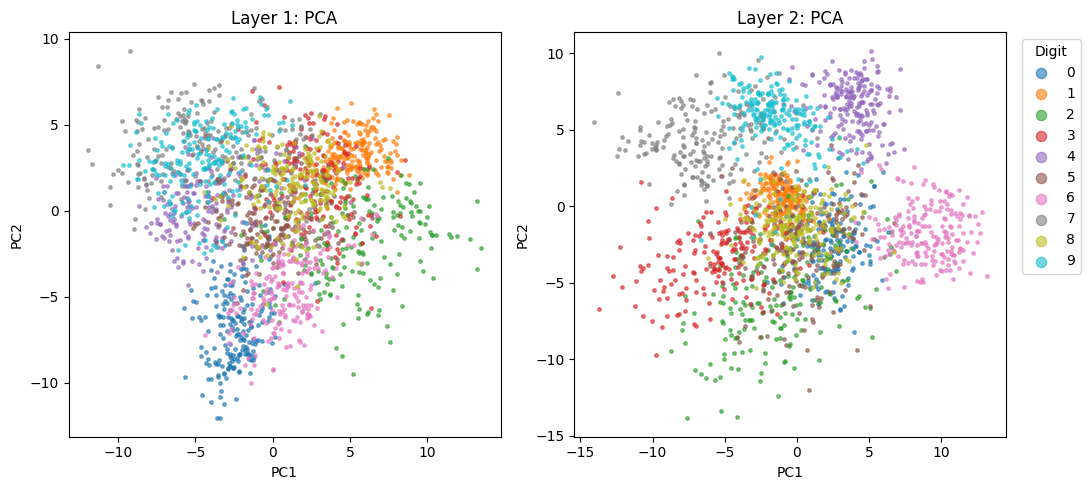

In [6]:
import numpy as np
import matplotlib.pyplot as plt

d = np.load("mnist_activations.npz")
y = d["y"]

def zscore(X):
    sd = X.std(axis=0)
    sd[sd == 0] = 1.0                     # dead units: avoid dividing by 0
    return (X - X.mean(axis=0)) / sd

def pca(X):
    Xc = X - X.mean(axis=0)
    eigvals, eigvecs = np.linalg.eigh(Xc.T @ Xc / len(Xc))
    order = np.argsort(eigvals)[::-1]
    return Xc @ eigvecs[:, order]         # PC scores (shadows), biggest spread first

fig, axes = plt.subplots(1, 2, figsize=(11, 5))
for ax, key, title in [(axes[0], "H1", "Layer 1"), (axes[1], "H2", "Layer 2")]:
    s = pca(zscore(d[key]))
    for digit in range(10):
        m = y == digit
        ax.scatter(s[m, 0], s[m, 1], s=6, alpha=0.6, color=plt.cm.tab10(digit), label=str(digit))
    ax.set(title=f"{title}: PCA", xlabel="PC1", ylabel="PC2")
axes[1].legend(title="Digit", bbox_to_anchor=(1.02, 1), loc="upper left", markerscale=3)
fig.tight_layout()
plt.show()

Layer 1: 6 dead units removed
Layer 2: 13 dead units removed


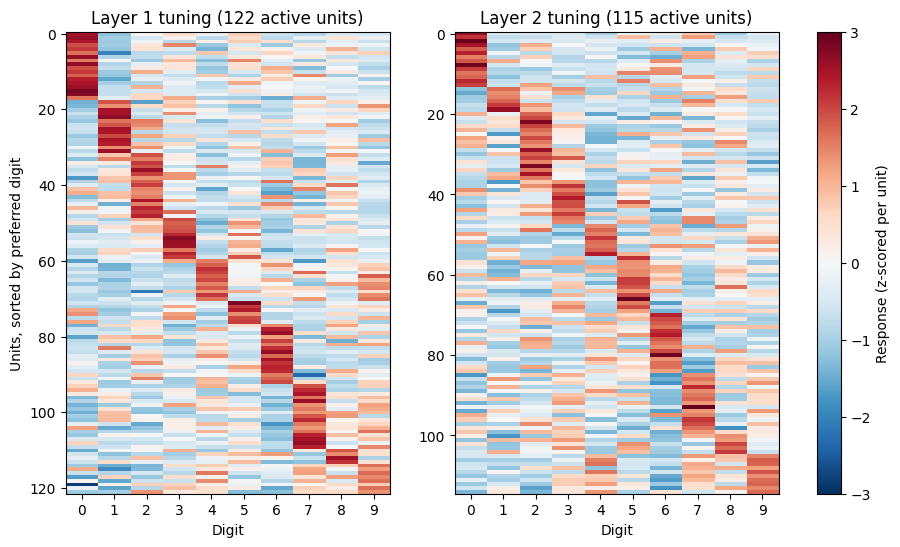

In [7]:
d = np.load("mnist_activations.npz")
y = d["y"]

fig, axes = plt.subplots(1, 2, figsize=(10, 6))
for ax, key, title in [(axes[0], "H1", "Layer 1"), (axes[1], "H2", "Layer 2")]:
    H = d[key]
    alive = H.max(axis=0) > 0                                         # drop units that never activate
    tuning = np.array([H[y == digit][:, alive].mean(axis=0) for digit in range(10)]).T   # units x 10 digits
    order = np.argsort(tuning.argmax(axis=1), kind="stable")          # sort by preferred digit
    t = tuning[order]
    t = (t - t.mean(axis=1, keepdims=True)) / (t.std(axis=1, keepdims=True) + 1e-12)   # rescale each unit
    im = ax.imshow(t, aspect="auto", cmap="RdBu_r", vmin=-3, vmax=3, interpolation="nearest")
    ax.set(title=f"{title} tuning ({alive.sum()} active units)", xlabel="Digit", xticks=range(10))
    print(f"{title}: {(~alive).sum()} dead units removed")
axes[0].set_ylabel("Units, sorted by preferred digit")
fig.colorbar(im, ax=axes, label="Response (z-scored per unit)", fraction=0.03)
plt.show()

Training VAE on Layer 1...
  epoch 100: rebuild error 61.5 | blob penalty 5.67
  epoch 200: rebuild error 55.1 | blob penalty 5.80
  epoch 300: rebuild error 50.7 | blob penalty 5.80
Training VAE on Layer 2...
  epoch 100: rebuild error 35.1 | blob penalty 5.91
  epoch 200: rebuild error 30.1 | blob penalty 5.92
  epoch 300: rebuild error 28.0 | blob penalty 5.80


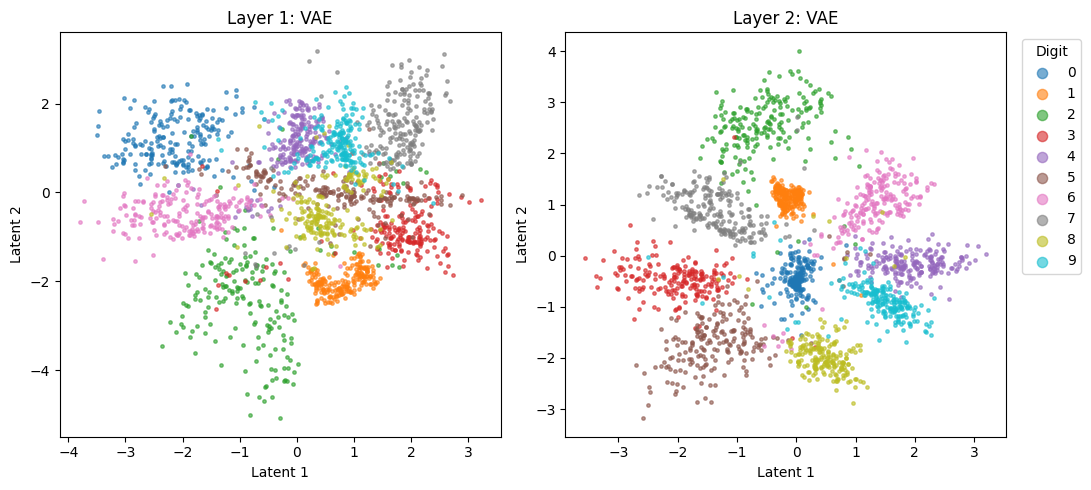

In [8]:
import numpy as np
import torch
import torch.nn as nn
import matplotlib.pyplot as plt

torch.manual_seed(0)
BETA = 1.0          # 1 = unconstrained (standard VAE)
EPOCHS = 300

d = np.load("mnist_activations.npz")
y = d["y"]

def zscore(X):
    sd = X.std(axis=0)
    sd[sd == 0] = 1.0                     # dead units: avoid dividing by 0
    return (X - X.mean(axis=0)) / sd

class VAE(nn.Module):
    def __init__(self, n_in, n_hidden=64):
        super().__init__()
        self.enc = nn.Sequential(nn.Linear(n_in, n_hidden), nn.ReLU())   # 128 -> 64
        self.center = nn.Linear(n_hidden, 2)                             # 64 -> 2 (the dot)
        self.log_var = nn.Linear(n_hidden, 2)                            # 64 -> 2 (the spread)
        self.dec = nn.Sequential(nn.Linear(2, n_hidden), nn.ReLU(), nn.Linear(n_hidden, n_in))  # 2 -> 128

    def forward(self, x):
        h = self.enc(x)
        mu, log_var = self.center(h), self.log_var(h)
        z = mu + torch.exp(0.5 * log_var) * torch.randn_like(mu)   # center + jitter
        return self.dec(z), mu, log_var

def train_vae(X):
    X = torch.tensor(X, dtype=torch.float32)
    vae = VAE(X.shape[1])
    opt = torch.optim.Adam(vae.parameters(), lr=1e-3)
    for epoch in range(1, EPOCHS + 1):
        for batch in torch.randperm(len(X)).split(128):
            x = X[batch]
            x_hat, mu, log_var = vae(x)
            rebuild = ((x - x_hat) ** 2).sum(dim=1).mean()                           # rebuild error
            blob = -0.5 * (1 + log_var - mu**2 - log_var.exp()).sum(dim=1).mean()    # blob penalty
            loss = rebuild + BETA * blob
            opt.zero_grad()
            loss.backward()
            opt.step()
        if epoch % 100 == 0:
            print(f"  epoch {epoch}: rebuild error {rebuild.item():.1f} | blob penalty {blob.item():.2f}")
    with torch.no_grad():
        return vae.center(vae.enc(X)).numpy()      # each image's 2D dot (the center)

fig, axes = plt.subplots(1, 2, figsize=(11, 5))
for ax, key, title in [(axes[0], "H1", "Layer 1"), (axes[1], "H2", "Layer 2")]:
    print(f"Training VAE on {title}...")
    z = train_vae(zscore(d[key]))
    for digit in range(10):
        m = y == digit
        ax.scatter(z[m, 0], z[m, 1], s=6, alpha=0.6, color=plt.cm.tab10(digit), label=str(digit))
    ax.set(title=f"{title}: VAE", xlabel="Latent 1", ylabel="Latent 2")
axes[1].legend(title="Digit", bbox_to_anchor=(1.02, 1), loc="upper left", markerscale=3)
fig.tight_layout()
plt.show()

Training VAE on Layer 1...
  epoch 100: rebuild error 91.3 | blob penalty 0.95
  epoch 200: rebuild error 85.6 | blob penalty 1.26
  epoch 300: rebuild error 81.9 | blob penalty 1.33
Training VAE on Layer 2...
  epoch 100: rebuild error 65.0 | blob penalty 1.57
  epoch 200: rebuild error 66.2 | blob penalty 1.65
  epoch 300: rebuild error 54.0 | blob penalty 1.79


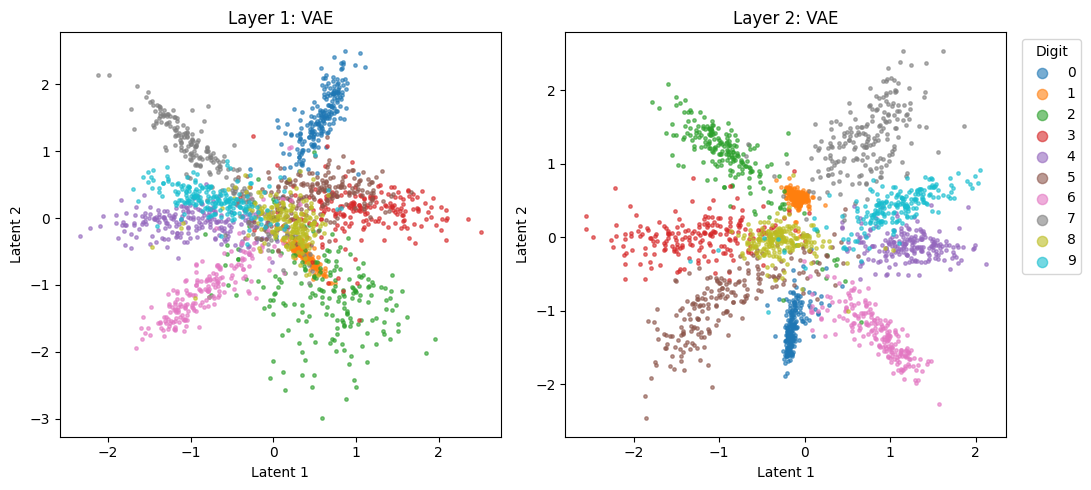

In [10]:
torch.manual_seed(0)
BETA = 20.0          
EPOCHS = 300

d = np.load("mnist_activations.npz")
y = d["y"]

def zscore(X):
    sd = X.std(axis=0)
    sd[sd == 0] = 1.0                     # dead units: avoid dividing by 0
    return (X - X.mean(axis=0)) / sd

class VAE(nn.Module):
    def __init__(self, n_in, n_hidden=64):
        super().__init__()
        self.enc = nn.Sequential(nn.Linear(n_in, n_hidden), nn.ReLU())   # 128 -> 64
        self.center = nn.Linear(n_hidden, 2)                             # 64 -> 2 (the dot)
        self.log_var = nn.Linear(n_hidden, 2)                            # 64 -> 2 (the spread)
        self.dec = nn.Sequential(nn.Linear(2, n_hidden), nn.ReLU(), nn.Linear(n_hidden, n_in))  # 2 -> 128

    def forward(self, x):
        h = self.enc(x)
        mu, log_var = self.center(h), self.log_var(h)
        z = mu + torch.exp(0.5 * log_var) * torch.randn_like(mu)   # center + jitter
        return self.dec(z), mu, log_var

def train_vae(X):
    X = torch.tensor(X, dtype=torch.float32)
    vae = VAE(X.shape[1])
    opt = torch.optim.Adam(vae.parameters(), lr=1e-3)
    for epoch in range(1, EPOCHS + 1):
        for batch in torch.randperm(len(X)).split(128):
            x = X[batch]
            x_hat, mu, log_var = vae(x)
            rebuild = ((x - x_hat) ** 2).sum(dim=1).mean()                           # rebuild error
            blob = -0.5 * (1 + log_var - mu**2 - log_var.exp()).sum(dim=1).mean()    # blob penalty
            loss = rebuild + BETA * blob
            opt.zero_grad()
            loss.backward()
            opt.step()
        if epoch % 100 == 0:
            print(f"  epoch {epoch}: rebuild error {rebuild.item():.1f} | blob penalty {blob.item():.2f}")
    with torch.no_grad():
        return vae.center(vae.enc(X)).numpy()      # each image's 2D dot (the center)

fig, axes = plt.subplots(1, 2, figsize=(11, 5))
for ax, key, title in [(axes[0], "H1", "Layer 1"), (axes[1], "H2", "Layer 2")]:
    print(f"Training VAE on {title}...")
    z = train_vae(zscore(d[key]))
    for digit in range(10):
        m = y == digit
        ax.scatter(z[m, 0], z[m, 1], s=6, alpha=0.6, color=plt.cm.tab10(digit), label=str(digit))
    ax.set(title=f"{title}: VAE", xlabel="Latent 1", ylabel="Latent 2")
axes[1].legend(title="Digit", bbox_to_anchor=(1.02, 1), loc="upper left", markerscale=3)
fig.tight_layout()
plt.show()